# IOE414 — Deep Learning Minor Project: Final Submission

## 🌿 Multi-Crop Leaf Disease Diagnosis: YOLOv8 + CNN with Grad-CAM

**Pipeline**: the user picks a leaf photo → the system identifies the **plant (tomato, corn, potato …)** → then the **disease (or healthy)** → using **two models** (YOLOv8 and a CNN with Grad-CAM) whose outputs are fused and explained.

**Course**: IOE414 – Deep Learning  
**Runs on**: Google Colab (GPU) with datasets stored in Google Drive  
**Team Members**: Sai Kushwant · Saiteja · Mahesh · Chenna Kesava

**Reference Paper**:
> *Tomato Health Monitoring System: Tomato Classification, Detection, and Counting System Based on YOLOv8 Model With Explainable MobileNet Models Using Grad-CAM++*, **IEEE Access**, Vol. 12, 2024. [DOI: 10.1109/ACCESS.2024.3351805](https://doi.org/10.1109/ACCESS.2024.3351805)

---

### Abstract
Most plant-disease demos train on a single crop, which makes the task easier and the numbers look better. In this project we go **multi-crop**: several datasets (different crops and diseases) are merged into one label space of the form `Crop___Disease`, so a single model must decide *which plant* a leaf belongs to **and** *which disease* it has. **Model 1 is YOLOv8** (`yolov8n-cls`); **Model 2 is a CNN** (custom-built or ResNet-18, selectable) with **Grad-CAM** heatmaps. Both are evaluated on the same held-out test set at three levels — plant identification, full class (plant + disease), and macro-F1 — and an interactive cell lets a user **upload any leaf image** and get the plant, the disease, a confidence score, and a heatmap showing where the CNN looked.

**All numbers in this notebook are computed when it is run — nothing is hard-coded.**

> ### ✅ What was fixed in this version
> The first run scored only ~53 % because of **data problems, not the models**:
> 1. `Data_sets/rice/` is an exact copy of the **corn** dataset (same 4 folders, same 1146/1306/574/1162 images). The model was asked to tell "Corn Blight" from "Rice Blight" on *identical pictures* → coin-flip accuracy. **Put a real rice-leaf dataset in `Data_sets/rice/`.** Until then the copy is detected and removed automatically.
> 2. The **potato** data was still inside `archive (1).zip`, so potato was never used. Zips are now unzipped automatically.
> 3. Tomato *Variant-b* became one fake class `Tomato___Variant-b(MultiLabel Classification)` (100 % accuracy only because those photos look different). Labels are now read from its CSV. Best option: also upload **Tomato-Village Variant-a** (multiclass folders), which is made for this task.
> 4. Tomato *Variant-c* (object detection, 2875 "corrupt" images) is now skipped instead of becoming a class.


## 1. Colab Setup, Environment & Configuration

**Before running anything**
1. **Turn on the GPU**: *Runtime → Change runtime type → T4 GPU*.
2. **Datasets in Drive**: upload your whole datasets folder (or a `.zip` of it) to Google Drive. Many small files copy slowly from Drive, so a **zip is much faster**.
3. Set `DRIVE_DATASET_DIR` (or `DRIVE_DATASET_ZIP`) in the *Dataset location* cell below.
4. Run the cells from top to bottom.

What happens automatically:
- Drive is mounted and the dataset is copied **once** to Colab's fast local disk (`/content/datasets`), so training never reads from Drive.
- Every image is **fully decoded and checked** before the train/val/test split is built; unreadable files are dropped and listed, so training cannot crash on a corrupt image.
- Models and result files are saved to **Drive** (`MyDrive/PlantDisease_Output`), so they survive a Colab disconnect.

Key switches in the configuration cell:
- `CROP_FILTER` – which crops to include (`None` = every crop found in the data).
- `MAX_PER_CLASS` – cap on images per class.
- `CNN_BACKBONE` – `"resnet18"` (pretrained, recommended) or `"custom"` (CNN built from scratch).
- `QUICK_RUN` – `True` = tiny smoke test to confirm the whole notebook runs end to end.

In [1]:
# Colab already has torch, torchvision, pandas, seaborn, scikit-learn ... only ultralytics + pi-heif are missing.
!pip install -q ultralytics pi-heif


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.7 MB/s eta 0:00:00


**Pre-flight check** – shows the GPU, confirms every package imports, and mounts Google Drive. If it says *No GPU*, switch the runtime to **T4 GPU** and run it again (training on CPU takes hours).

In [2]:
import os, sys
os.environ["YOLO_AUTOINSTALL"] = "False"     # must be set before ultralytics is imported
import importlib, importlib.util

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

import torch
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("!! No GPU found. Runtime > Change runtime type > T4 GPU, then run this cell again.")

problems = []
for pkg in ["numpy", "pandas", "PIL", "matplotlib", "seaborn", "sklearn", "torchvision", "tqdm", "ultralytics"]:
    try:
        importlib.import_module(pkg); print(f"  {pkg:<12} OK")
    except ImportError as e:
        problems.append(pkg); print(f"  {pkg:<12} MISSING ({e})")
print("\nAll packages OK." if not problems else f"\nInstall these first: {problems}")

if IN_COLAB:
    drive.mount("/content/drive")

Running in Colab: True
Python 3.13.15 | PyTorch 2.11.0+cu130
GPU: Tesla T4
  numpy        OK
  pandas       OK
  PIL          OK
  matplotlib   OK
  seaborn      OK
  sklearn      OK
  torchvision  OK
  tqdm         OK
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
  ultralytics  OK

All packages OK.
Mounted at /content/drive


In [3]:
import os
from collections import Counter
ROOT = "/content/drive/MyDrive/Data_sets"   # change if your folder has a different name
for d, _, files in sorted(os.walk(ROOT)):
    if files:
        ext = Counter(os.path.splitext(f)[1].lower() for f in files)
        print(f"{os.path.relpath(d, ROOT):<80} {len(files):>6} files  {dict(ext.most_common(3))}")

corn/Blight                                                                        1146 files  {'.jpg': 1145, '.jpeg': 1}
corn/Common_Rust                                                                   1306 files  {'.jpg': 1306}
corn/Gray_Leaf_Spot                                                                 575 files  {'.jpg': 575}
corn/Healthy                                                                       1162 files  {'.jpg': 1162}
rice/Bacterialblight                                                               1584 files  {'.jpg': 1584}
rice/Blast                                                                         1441 files  {'.jpg': 1441}
rice/Brownspot                                                                     1600 files  {'.jpg': 1600}
rice/Tungro                                                                        1308 files  {'.jpg': 1308}
tomato                                                                                1 files  {'.md': 1}
tom

In [4]:
import os
os.environ["YOLO_AUTOINSTALL"] = "False"   # stop Ultralytics from running pip installs

import io, json, time, shutil, random, zipfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True      # tolerate partially-written JPEGs (same setting used in training)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.model_selection import train_test_split

from ultralytics import YOLO
import ultralytics

# ---------------- Global configuration ----------------
QUICK_RUN     = False        # True = smoke test (1 epoch, tiny data)
CNN_BACKBONE  = "resnet18"   # "resnet18" (pretrained, recommended) or "custom" (from scratch)
CROP_FILTER   = ["tomato", "corn", "potato", "rice"]   # substrings of crop names; None = all crops
MAX_PER_CLASS = 400          # cap images per class
MIN_PER_CLASS = 20           # drop classes with fewer images than this
CNN_EPOCHS    = 20
YOLO_EPOCHS   = 15
BATCH_SIZE    = 64
IMG_SIZE      = 224
RANDOM_SEED   = 42

if QUICK_RUN:
    CNN_EPOCHS, YOLO_EPOCHS, MAX_PER_CLASS, MIN_PER_CLASS = 1, 1, 40, 10

random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = min(2, os.cpu_count() or 1) if IN_COLAB else 0

# ---------------- Folders ----------------
# WORK_DIR = fast local disk (temporary). OUT_DIR = Google Drive (kept after the session ends).
WORK_DIR = Path("/content/work") if IN_COLAB else Path(".")
OUT_DIR  = Path("/content/drive/MyDrive/PlantDisease_Output") if IN_COLAB else Path(".")
RESULTS_DIR = OUT_DIR / "results";  RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR  = OUT_DIR / "models";   MODELS_DIR.mkdir(parents=True, exist_ok=True)
UPLOAD_DIR  = WORK_DIR / "uploads"; UPLOAD_DIR.mkdir(parents=True, exist_ok=True)
YOLO_DIR    = WORK_DIR / "yolo_data"
RUNS_DIR    = WORK_DIR / "runs"
CNN_NAME = "Custom CNN" if CNN_BACKBONE == "custom" else "ResNet-18"

print(f"PyTorch {torch.__version__} | Torchvision {torchvision.__version__} | Ultralytics {ultralytics.__version__}")
print(f"Device: {device} | CNN backbone: {CNN_NAME} | QUICK_RUN: {QUICK_RUN} | workers: {NUM_WORKERS}")
print(f"Outputs will be saved to: {OUT_DIR.resolve()}")

PyTorch 2.11.0+cu130 | Torchvision 0.26.0+cu130 | Ultralytics 8.4.183
Device: cuda | CNN backbone: ResNet-18 | QUICK_RUN: False | workers: 2
Outputs will be saved to: /content/drive/MyDrive/PlantDisease_Output


## 2. Multi-Dataset Pipeline (everything in ONE dataset folder)

Put **all** your datasets inside one Drive folder. The notebook scans every sub-folder automatically — you do not list datasets one by one.


Every folder that directly contains images becomes one class, converted to **`Crop___Disease`** (e.g. `Tomato___Late blight`). The **crop** is worked out in this order:
1. the folder name itself (`Tomato___Late_blight`, `Tomato__Target_Spot`);
2. your `FOLDER_CROP_MAP` (e.g. `{"Variant-a": "Tomato"}` for a dataset with plain disease names);
3. `Tomato_healthy`-style names, or a known crop name (tomato, corn, potato …) in a parent folder.

Folders whose crop cannot be determined are **skipped and listed**. Folders with a generic name (`Images`, `data` …) take their disease name from the parent folder, and a warning is printed if a generic class name is still left. The same class from different datasets is merged automatically.

**Data checks added (fix for the ~50 % accuracy of the first run):**
- `.zip` files inside the dataset folder are unzipped automatically (the potato zip was never opened before).
- Datasets labelled by a **CSV** (Tomato-Village *Variant-b*) get their real disease labels from the CSV; multi-label images are left out.
- **Object-detection** folders (*Variant-c*: `images/` + `yolo/` / `pascal_voc/`) are skipped — they are not classification data.
- Every image is fingerprinted (MD5). If the **same picture appears under two crops** (e.g. a `rice` folder that is really a copy of the corn dataset) a loud warning is printed and the copy is removed. Exact duplicates are also removed so they cannot leak from train into test.


### 2.1 Dataset location (Google Drive → Colab local disk)

Set **one** of the two options. The data is copied/unzipped to `/content/datasets` only once per session.

In [5]:
# ---- EDIT THIS: where your datasets are in Google Drive ----
DRIVE_DATASET_DIR = "/content/drive/MyDrive/Data_sets"   # option A: a folder containing all datasets
DRIVE_DATASET_ZIP = ""                                   # option B (faster): e.g. "/content/drive/MyDrive/Data_sets.zip"

LOCAL_DATASET_DIR = Path("/content/datasets") if IN_COLAB else Path(DRIVE_DATASET_DIR)

if IN_COLAB:
    marker = LOCAL_DATASET_DIR / ".copy_done"
    if marker.exists():
        print("Dataset already on local disk:", LOCAL_DATASET_DIR)
    else:
        shutil.rmtree(LOCAL_DATASET_DIR, ignore_errors=True)
        LOCAL_DATASET_DIR.mkdir(parents=True)
        t0 = time.time()
        if DRIVE_DATASET_ZIP and Path(DRIVE_DATASET_ZIP).exists():
            print("Unzipping", DRIVE_DATASET_ZIP, "...")
            with zipfile.ZipFile(DRIVE_DATASET_ZIP) as z:
                z.extractall(LOCAL_DATASET_DIR)
        elif Path(DRIVE_DATASET_DIR).exists():
            print("Copying", DRIVE_DATASET_DIR, "to local disk (one-time, can take several minutes) ...")
            shutil.copytree(DRIVE_DATASET_DIR, LOCAL_DATASET_DIR, dirs_exist_ok=True)
        else:
            print("Dataset not found. Folders directly under MyDrive are:")
            for p in sorted(Path("/content/drive/MyDrive").iterdir())[:40]:
                print("   ", p.name)
            raise FileNotFoundError(f"{DRIVE_DATASET_DIR} does not exist. Fix DRIVE_DATASET_DIR (or DRIVE_DATASET_ZIP).")
        marker.touch()
        print(f"Done in {time.time() - t0:.0f}s")

# ---- Unzip any .zip files that are INSIDE the dataset folder (e.g. the potato zip) ----
# Before this fix, zips sitting in Data_sets/ were never opened, so their images were silently missing.
# If a zip's internal folders do not say which crop it is (e.g. corn zip = data/Blight, data/Healthy ...),
# name the crop here: zip file name -> crop folder it should be extracted into.
ZIP_CROP_MAP = {
    "archive.zip": "corn",          # data/Blight, data/Common_Rust ... (maize leaf disease dataset)
    # "archive (1).zip": "potato",  # not needed: its folders are already named Potato___Early_blight ...
}
_KNOWN = ["tomato", "corn", "maize", "potato", "rice", "wheat", "apple", "grape", "pepper", "cotton"]

for zp in sorted(LOCAL_DATASET_DIR.rglob("*.zip")):
    done = zp.with_name(zp.name + ".extracted")
    if done.exists():
        continue
    with zipfile.ZipFile(zp) as z:
        names = z.namelist()
        crop_in_names = any(k in n.lower() for n in names[:500] for k in _KNOWN)
        if zp.name in ZIP_CROP_MAP:
            target = zp.parent / ZIP_CROP_MAP[zp.name]
        elif crop_in_names:
            target = zp.parent / zp.stem
        else:
            target = zp.parent / f"UNKNOWN_CROP_{zp.stem}"
            print(f"[warning] {zp.name}: cannot tell which crop it is -> add it to ZIP_CROP_MAP")
        print(f"Unzipping {zp.relative_to(LOCAL_DATASET_DIR)}  ->  {target.relative_to(LOCAL_DATASET_DIR)}/  ({len(names):,} entries)")
        z.extractall(target)
    done.touch()

n_img = sum(1 for _ in LOCAL_DATASET_DIR.rglob("*") if _.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"})
print(f"{n_img:,} image files available after unzipping")

Copying /content/drive/MyDrive/Data_sets to local disk (one-time, can take several minutes) ...
Done in 432s
18,650 image files available after unzipping


In [6]:
!pip install pi-heif

In [7]:
# ---- Quiet logs + HEIC support ----
import logging, warnings, hashlib, re
logging.getLogger("ultralytics").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")
try:
    import pillow_heif
    pillow_heif.register_heif_opener()    # lets Pillow read HEIC photos saved with a .jpg name
except ImportError:
    print("pi-heif not installed: run  !pip install pi-heif  and restart the session")

# ---- Dataset settings ----
DATASET_DIR = LOCAL_DATASET_DIR

# Which crop a dataset belongs to when its folders are plain disease names.
# Key = any text found in the folder path (case-insensitive), value = crop name.
FOLDER_CROP_MAP = {
    "Variant-a": "Tomato",
    "Variant-b": "Tomato",
}
# Object-detection datasets (boxes, not image labels) and duplicate PlantVillage variants are skipped.
IGNORE_PATH_KEYWORDS = ["grayscale", "segmented", "object detection", "unknown_crop_"]
DETECTION_SIBLINGS   = {"labels", "yolo", "pascal_voc", "annotations", "xml"}   # images/ next to these = detection data
GENERIC_FOLDERS = {"images", "image", "imgs", "img", "data", "photos", "train", "training", "test", "val",
                   "valid", "validation", "dataset"}
# If the SAME image file appears under two different crops (e.g. a "rice" folder that is really a copy of
# the corn dataset), it is kept only under the crop that comes first in this list.
DUPLICATE_KEEP_CROP_ORDER = ["Corn (maize)", "Potato", "Tomato", "Rice"]

KNOWN_CROPS = ["tomato", "corn", "maize", "potato", "apple", "grape", "pepper", "cherry", "peach",
               "strawberry", "soybean", "squash", "orange", "blueberry", "raspberry", "rice", "wheat",
               "cotton", "cucumber", "mango", "banana", "sugarcane", "coffee", "cassava"]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def _clean(s):
    return " ".join(s.replace(",", " ").replace("_", " ").split())

def _norm_crop(crop):
    crop = _clean(crop)
    if crop.lower().startswith(("corn", "maize")):
        return "Corn (maize)"
    return crop[:1].upper() + crop[1:].lower()

def _norm_dis(dis):
    dis = _clean(dis)
    return dis[:1].upper() + dis[1:] if dis else "Unknown"

def crop_from_parts(parts):
    path_lower = " / ".join(parts).lower()
    for key, val in FOLDER_CROP_MAP.items():
        if key.lower() in path_lower:
            return val
    for part in reversed(parts):
        hit = next((k for k in KNOWN_CROPS if k in part.lower()), None)
        if hit:
            return hit
    return None

def infer_label(class_dir, root):
    # 'Crop___Disease' for a folder of images, or None if the crop is unknown.
    folder = class_dir.name
    parts = (root.name,) + class_dir.relative_to(root).parts[:-1]
    crop = dis = None
    if "___" in folder or "__" in folder:
        crop, dis = folder.split("___", 1) if "___" in folder else folder.split("__", 1)
    elif "_" in folder and folder.split("_")[0].lower() in KNOWN_CROPS:
        crop, dis = folder.split("_", 1)
    else:
        crop, dis = crop_from_parts(parts), folder
    if crop is None:
        return None
    return f"{_norm_crop(crop)}___{_norm_dis(dis)}"

root = Path(DATASET_DIR)
if not root.exists():
    raise FileNotFoundError(f"Dataset folder not found: {root.resolve()}  ->  check the Dataset location cell.")
skip_rel = lambda p: any(k in "/".join(p.relative_to(root).parts).lower() for k in IGNORE_PATH_KEYWORDS)

# ---- 1) CSV-labelled datasets (e.g. Tomato-Village Variant-b: images in train/val/test + one labels CSV) ----
# Before this fix, the whole Variant-b folder became ONE fake class "Tomato___Variant-b(MultiLabel ...)".
# Now the real disease of each image is read from the CSV; images with more than one disease are left out
# (this notebook is single-label classification).
records, csv_covered, skipped = [], set(), {}
for csv_path in sorted(root.rglob("*.csv")):
    if skip_rel(csv_path):
        continue
    try:
        meta = pd.read_csv(csv_path)
    except Exception as e:
        print(f"[info] could not read {csv_path.name}: {e}"); continue
    imgs_here = {p.name: p for p in csv_path.parent.rglob("*") if p.suffix.lower() in IMG_EXT}
    if not imgs_here:
        continue
    fcol = max(meta.columns, key=lambda c: meta[c].astype(str).map(lambda v: Path(v).name in imgs_here).mean())
    if meta[fcol].astype(str).map(lambda v: Path(v).name in imgs_here).mean() < 0.5:
        continue                                            # not a labels file for these images
    crop = crop_from_parts((root.name,) + csv_path.parent.relative_to(root).parts)
    if crop is None:
        skipped[str(csv_path.relative_to(root))] = len(imgs_here); continue
    other = [c for c in meta.columns if c != fcol]
    onehot = [c for c in other if set(pd.to_numeric(meta[c], errors="coerce").dropna().unique()) <= {0, 1}
              and pd.to_numeric(meta[c], errors="coerce").notna().all()]
    n_multi = n_none = 0
    for _, r in meta.iterrows():
        p = imgs_here.get(Path(str(r[fcol])).name)
        if p is None:
            continue
        csv_covered.add(str(p))
        if onehot:                                          # multi-hot columns: one column per disease
            on = [c for c in onehot if int(r[c]) == 1]
        else:                                               # a text column such as "labels": "Early_blight;Leaf_Miner"
            txt = str(r[other[0]]) if other else ""
            on = [t for t in re.split(r"[;,|]\s*", txt) if t and t.lower() != "nan"]
        if len(on) == 1:
            records.append((str(p), f"{_norm_crop(crop)}___{_norm_dis(on[0])}"))
        elif len(on) > 1:
            n_multi += 1
        else:
            n_none += 1
    print(f"[csv] {csv_path.relative_to(root)}: label columns {onehot or other[:1]} -> "
          f"{sum(1 for p, _ in records if p in csv_covered):,} single-label images used, "
          f"{n_multi} multi-label + {n_none} unlabelled skipped")

# ---- 2) folder-labelled datasets ----
det_skipped = {}
for dirpath, dirnames, files in os.walk(root):
    cdir = Path(dirpath)
    imgs = [f for f in files if Path(f).suffix.lower() in IMG_EXT and str(cdir / f) not in csv_covered]
    if not imgs or skip_rel(cdir):
        continue
    siblings = {d.name.lower() for d in cdir.parent.iterdir() if d.is_dir()}
    if cdir.name.lower() in {"images", "imgs", "img"} and siblings & DETECTION_SIBLINGS:
        det_skipped[str(cdir.relative_to(root))] = len(imgs); continue
    label_dir = cdir
    while label_dir.name.lower() in GENERIC_FOLDERS and label_dir.parent != root and label_dir != root:
        label_dir = label_dir.parent
    label = infer_label(label_dir, root)
    if label is None:
        skipped[str(cdir.relative_to(root))] = len(imgs); continue
    records += [(str(cdir / f), label) for f in imgs]

if det_skipped:
    print(f"[info] skipped object-detection image folders (they need box training, not classification): {det_skipped}")
if skipped:
    print(f"[warning] {len(skipped)} folder(s) skipped - crop unknown. Add a keyword to FOLDER_CROP_MAP:")
    for k, v in list(skipped.items())[:15]:
        print(f"    {k}  ({v} images)")
if not records:
    raise FileNotFoundError("No usable images found in DATASET_DIR (see warnings above).")

df_all = pd.DataFrame(records, columns=["path", "label"])
df_all["src"] = 0
df_all["crop"] = df_all["label"].str.split("___").str[0]
print(f"Found {len(df_all):,} images in {df_all['label'].nunique()} classes / {df_all['crop'].nunique()} crops")

if CROP_FILTER:
    keep = df_all["crop"].str.lower().apply(lambda c: any(k.lower() in c for k in CROP_FILTER))
    df_all = df_all[keep].reset_index(drop=True)

# ---- 3) fully decode every image + fingerprint it (MD5) ----
def _check(p):
    try:
        with open(p, "rb") as f:
            data = f.read()
        if not data:
            return "empty file", None
        with Image.open(io.BytesIO(data)) as im:
            im.convert("RGB")
        return "ok", hashlib.md5(data).hexdigest()
    except Exception:
        try:
            return ("HEIC/HEIF (needs pi-heif)" if data[4:8] == b"ftyp" else "corrupt / not an image"), None
        except Exception:
            return "cannot open file", None

with ThreadPoolExecutor(max_workers=8) as ex:
    res = list(tqdm(ex.map(_check, df_all["path"]), total=len(df_all), desc="Checking images"))
df_all["status"] = [s for s, _ in res]
df_all["md5"]    = [h for _, h in res]
bad_df = df_all[df_all["status"] != "ok"]
if len(bad_df):
    (RESULTS_DIR / "bad_images.txt").write_text("\n".join(bad_df["path"]))
    print(f"[info] removed {len(bad_df)} unreadable image(s) (list in bad_images.txt)")
    print("  reasons :", bad_df["status"].value_counts().to_dict())
    print("  classes :", bad_df["label"].value_counts().to_dict())
df_all = df_all[df_all["status"] == "ok"].reset_index(drop=True)

# ---- 4) duplicate check ----
# (a) the same picture copied under two different crops = a mislabelled dataset copy -> warn loudly
crop_sets = df_all.groupby("crop")["md5"].apply(set).to_dict()
for a in crop_sets:
    for b in crop_sets:
        if a < b:
            shared = len(crop_sets[a] & crop_sets[b])
            if shared:
                frac = shared / min(len(crop_sets[a]), len(crop_sets[b]))
                print(f"[WARNING] {shared:,} identical images appear under BOTH '{a}' and '{b}' ({frac:.0%} of the "
                      f"smaller crop).{'  -> one of these folders is a COPY of the other dataset; replace it with the real one!' if frac > 0.5 else ''}")
order = {c: i for i, c in enumerate(DUPLICATE_KEEP_CROP_ORDER)}
df_all["_prio"] = df_all["crop"].map(lambda c: order.get(c, len(order)))
n0 = len(df_all)
# (b) keep each picture once: removes cross-crop copies AND exact duplicates that would leak between train and test
df_all = (df_all.sort_values(["_prio", "path"]).drop_duplicates("md5", keep="first")
                .drop(columns=["_prio", "status"]).reset_index(drop=True))
print(f"[info] removed {n0 - len(df_all):,} duplicate image(s); {len(df_all):,} unique images remain")

# ---- 5) drop tiny classes, cap per class ----
counts = df_all["label"].value_counts()
dropped = counts[counts < MIN_PER_CLASS]
if len(dropped):
    print(f"[info] dropped classes with fewer than {MIN_PER_CLASS} images: {dropped.to_dict()}")
df_all = df_all[df_all["label"].isin(counts[counts >= MIN_PER_CLASS].index)]
df_all = pd.concat([g.sample(min(len(g), MAX_PER_CLASS), random_state=RANDOM_SEED)
                    for _, g in df_all.groupby("label")]).reset_index(drop=True)
df_all["crop"] = df_all["label"].str.split("___").str[0]

missing = [k for k in (CROP_FILTER or []) if not df_all["crop"].str.lower().str.contains(k.lower()).any()]
if missing:
    print(f"[WARNING] no usable images for: {missing}  (check that dataset is in Drive / unzipped / not a copy)")
suspicious = [c for c in df_all["label"].unique()
              if c.split("___")[1].lower() in GENERIC_FOLDERS or "variant" in c.lower() or "classification" in c.lower()]
if suspicious:
    print(f"[WARNING] these class names look like dataset folder names, not diseases: {suspicious}")

# ---- 6) stratified 70/15/15 split ----
train_df, temp_df = train_test_split(df_all, test_size=0.30, stratify=df_all["label"], random_state=RANDOM_SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=RANDOM_SEED)

# ---- 7) build yolo_data/{train,val,test}/<label>/ on the local disk ----
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)
for split, sdf in [("train", train_df), ("val", val_df), ("test", test_df)]:
    for n, (p, lab, si) in enumerate(tqdm(list(zip(sdf["path"], sdf["label"], sdf["src"])), desc=f"Copying {split}")):
        dst = YOLO_DIR / split / lab
        dst.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, dst / f"s{si}_{n}_{Path(p).name}")

# ---- 8) class bookkeeping ----
CLASS_NAMES   = sorted(df_all["label"].unique())
NUM_CLASSES   = len(CLASS_NAMES)
CLASS_CROP    = [c.split("___")[0] for c in CLASS_NAMES]
CLASS_DISEASE = [c.split("___")[1] for c in CLASS_NAMES]
CROPS_LIST    = sorted(set(CLASS_CROP))
CLASS_CROP_IDX = np.array([CROPS_LIST.index(c) for c in CLASS_CROP])
CROP_MATRIX = np.zeros((NUM_CLASSES, len(CROPS_LIST)), dtype=np.float32)
CROP_MATRIX[np.arange(NUM_CLASSES), CLASS_CROP_IDX] = 1.0
json.dump({"classes": CLASS_NAMES}, open(MODELS_DIR / "classes.json", "w"), indent=1)

print(f"\nUsing {NUM_CLASSES} classes across {len(CROPS_LIST)} crops: {CROPS_LIST}\n")
split_tbl = pd.DataFrame({"train": train_df["label"].value_counts(),
                          "val":   val_df["label"].value_counts(),
                          "test":  test_df["label"].value_counts()}).fillna(0).astype(int).sort_index()
split_tbl.loc["TOTAL"] = split_tbl.sum()
display(split_tbl)


pi-heif not installed: run  !pip install pi-heif  and restart the session
[csv] tomato/Variant-b(MultiLabel Classification)/Multi-Label dataset - with augmented.csv: label columns ['dataset'] -> 5,653 single-label images used, 0 multi-label + 0 unlabelled skipped
Found 15,775 images in 11 classes / 3 crops


Checking images:   0%|          | 0/15775 [00:00<?, ?it/s]

[info] removed 1,142 duplicate image(s); 14,633 unique images remain
[WARNING] no usable images for: ['potato']  (check that dataset is in Drive / unzipped / not a copy)
[WARNING] these class names look like dataset folder names, not diseases: ['Tomato___Test', 'Tomato___Train', 'Tomato___Val']


Copying train:   0%|          | 0/3080 [00:00<?, ?it/s]

Copying val:   0%|          | 0/660 [00:00<?, ?it/s]

Copying test:   0%|          | 0/660 [00:00<?, ?it/s]


Using 11 classes across 3 crops: ['Corn (maize)', 'Rice', 'Tomato']



,train,val,test
label,,,
Corn (maize)___Blight,280,60,60
Corn (maize)___Common Rust,280,60,60
Corn (maize)___Gray Leaf Spot,280,60,60
Corn (maize)___Healthy,280,60,60
Rice___Bacterialblight,280,60,60
Rice___Blast,280,60,60
Rice___Brownspot,280,60,60
Rice___Tungro,280,60,60
Tomato___Test,280,60,60


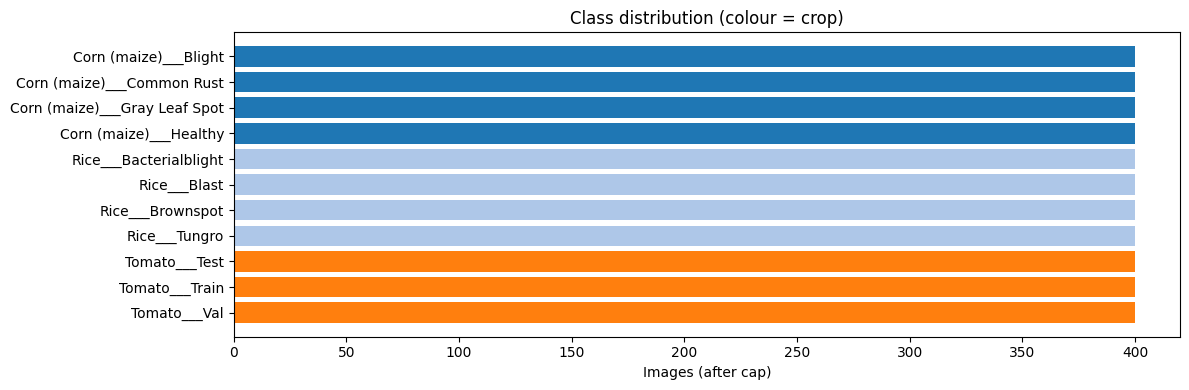

In [8]:
fig, ax = plt.subplots(figsize=(12, max(4, 0.28 * NUM_CLASSES)))
cnt = df_all["label"].value_counts().reindex(CLASS_NAMES)
ax.barh(CLASS_NAMES, cnt.values, color=[plt.cm.tab20(CROPS_LIST.index(c) % 20) for c in CLASS_CROP])
ax.set_xlabel("Images (after cap)"); ax.set_title("Class distribution (colour = crop)"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "class_distribution.png", dpi=150); plt.show()

## 3. Augmentation & Loaders (CNN branch)

Resize 224×224 · random flip · ±15° rotation · brightness/contrast jitter · ImageNet normalisation. (YOLOv8 uses its own built-in augmentation.)

In [9]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(15), transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_dataset = datasets.ImageFolder(YOLO_DIR / "train", transform=train_transform)
val_dataset   = datasets.ImageFolder(YOLO_DIR / "val",   transform=eval_transform)
test_dataset  = datasets.ImageFolder(YOLO_DIR / "test",  transform=eval_transform)
assert train_dataset.classes == CLASS_NAMES, "class order mismatch"

if QUICK_RUN:
    rng = np.random.RandomState(RANDOM_SEED)
    pick = lambda ds, n: Subset(ds, rng.choice(len(ds), min(n, len(ds)), replace=False).tolist())
    train_ds_used, val_ds_used = pick(train_dataset, 256), pick(val_dataset, 128)
else:
    train_ds_used, val_ds_used = train_dataset, val_dataset

train_loader = DataLoader(train_ds_used, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
val_loader   = DataLoader(val_ds_used,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
print(f"Train / Val / Test images: {len(train_ds_used)} / {len(val_ds_used)} / {len(test_dataset)}")

Train / Val / Test images: 3080 / 660 / 660


## 4. Model 1 — YOLOv8 (`yolov8n-cls`)

The YOLOv8 **classification** variant (CSP/C2f backbone, ImageNet-pretrained) fine-tuned end-to-end on all `Crop___Disease` classes. We use the classification head because the datasets have image-level labels (no bounding boxes). With box-annotated data the same pipeline can switch to detection (`yolov8n.pt`) for lesion localisation and counting.

In [10]:
yolo_model = YOLO("yolov8n-cls.pt")
t0 = time.time()
yolo_model.train(
    data=str(YOLO_DIR.resolve()), epochs=YOLO_EPOCHS, imgsz=IMG_SIZE, batch=BATCH_SIZE,
    seed=RANDOM_SEED, workers=NUM_WORKERS, device=0 if torch.cuda.is_available() else "cpu",
    project=str(RUNS_DIR.resolve()), name="yolov8_cls", exist_ok=True, plots=True, verbose=False)
yolo_train_time = time.time() - t0

YOLO_BEST = RUNS_DIR / "yolov8_cls" / "weights" / "best.pt"
shutil.copy2(YOLO_BEST, MODELS_DIR / "best_yolov8n_cls.pt")
yolo_model = YOLO(str(YOLO_BEST))
y_total = sum(p.numel() for p in yolo_model.model.parameters())
print(f"\nYOLOv8 training time: {yolo_train_time:.1f}s | parameters: {y_total:,} | classes: {len(yolo_model.names)}")


YOLOv8 training time: 320.7s | parameters: 1,452,379 | classes: 11


## 5. Model 2 — CNN (selectable backbone)

- **`custom`**: a CNN designed from scratch — a stride-2 stem plus 4 blocks of *Conv-BN-ReLU ×2* (32→32→64→128→256 channels, final 14×14 feature maps), global average pooling, dropout, linear head. No pretrained weights. The stride-2 stem keeps it light and fast.
- **`resnet18`**: ImageNet-pretrained ResNet-18, early layers frozen, `layer4` + a new head fine-tuned (**recommended** — a from-scratch CNN needs far more data/epochs to get high accuracy).

Set `CNN_BACKBONE` in the configuration cell. Grad-CAM automatically targets the last convolutional block of whichever backbone is used.

In [11]:
def conv_block(cin, cout, pool=True):
    layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=False),
              nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=False)]
    if pool:
        layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

class PlantCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.stem   = nn.Sequential(nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False),
                                    nn.BatchNorm2d(32), nn.ReLU(inplace=False))   # 224 -> 112
        self.block1 = conv_block(32, 32)                  # 112 -> 56
        self.block2 = conv_block(32, 64)                  #  56 -> 28
        self.block3 = conv_block(64, 128)                 #  28 -> 14
        self.block4 = conv_block(128, 256, pool=False)    #  14x14 maps  <- Grad-CAM target
        self.gap  = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(0.4)
        self.fc   = nn.Linear(256, num_classes)
    def forward(self, x):
        x = self.block4(self.block3(self.block2(self.block1(self.stem(x)))))
        return self.fc(self.drop(self.gap(x).flatten(1)))

def build_cnn(backbone, num_classes):
    if backbone == "custom":
        return PlantCNN(num_classes).to(device)
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for p in m.parameters(): p.requires_grad = False
    for p in m.layer4.parameters(): p.requires_grad = True
    m.fc = nn.Sequential(nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, num_classes))
    return m.to(device)

def gradcam_target(model):
    return model.block4 if hasattr(model, "block4") else model.layer4[-1]

cnn_model = build_cnn(CNN_BACKBONE, NUM_CLASSES)
c_total = sum(p.numel() for p in cnn_model.parameters())
c_train = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
print(f"{CNN_NAME}: total params {c_total:,} | trainable {c_train:,} ({100*c_train/c_total:.1f}%)")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


ResNet-18: total params 11,310,667 | trainable 8,527,883 (75.4%)


## 6. CNN Training

Class-weighted `CrossEntropyLoss` (balances rare classes) · `AdamW` · cosine learning-rate schedule · best-validation checkpoint saved to `models/`.

In [12]:
counts = np.bincount(train_dataset.targets, minlength=NUM_CLASSES).clip(min=1)
class_weights = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
LR = 1e-3 if CNN_BACKBONE == "custom" else 3e-4
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, cnn_model.parameters()), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CNN_EPOCHS)

def run_epoch(model, loader, train=True):
    model.train(train)
    loss_sum, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train: optimizer.zero_grad()
            out = model(x); loss = criterion(out, y)
            if train:
                loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return loss_sum / n, correct / n

CNN_BEST = MODELS_DIR / "best_cnn_plant_model.pth"
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, t0 = 0.0, time.time()
for epoch in range(1, CNN_EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(cnn_model, train_loader, True)
    va_loss, va_acc = run_epoch(cnn_model, val_loader, False)
    scheduler.step()
    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]): history[k].append(v)
    if va_acc >= best_val_acc:
        best_val_acc = va_acc; torch.save(cnn_model.state_dict(), CNN_BEST)
    print(f"Epoch {epoch:02d}/{CNN_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")
cnn_train_time = time.time() - t0
cnn_model.load_state_dict(torch.load(CNN_BEST, map_location=device)); cnn_model.eval()
print(f"\nCNN training time: {cnn_train_time:.1f}s | best val acc: {best_val_acc:.4f}")

Epoch 01/20 | train loss 0.8705 acc 0.6825 | val loss 0.4485 acc 0.7773
Epoch 02/20 | train loss 0.4340 acc 0.7916 | val loss 0.4454 acc 0.7727
Epoch 03/20 | train loss 0.3937 acc 0.8081 | val loss 0.3768 acc 0.7864
Epoch 04/20 | train loss 0.3590 acc 0.8256 | val loss 0.3956 acc 0.8015
Epoch 05/20 | train loss 0.3221 acc 0.8412 | val loss 0.3877 acc 0.8076
Epoch 06/20 | train loss 0.3050 acc 0.8542 | val loss 0.4092 acc 0.8091
Epoch 07/20 | train loss 0.2928 acc 0.8649 | val loss 0.4486 acc 0.8121
Epoch 08/20 | train loss 0.2513 acc 0.8870 | val loss 0.4686 acc 0.7924
Epoch 09/20 | train loss 0.2520 acc 0.8942 | val loss 0.5320 acc 0.8167
Epoch 10/20 | train loss 0.1958 acc 0.9208 | val loss 0.5539 acc 0.8182
Epoch 11/20 | train loss 0.1563 acc 0.9412 | val loss 0.6065 acc 0.7985
Epoch 12/20 | train loss 0.1413 acc 0.9490 | val loss 0.6499 acc 0.8136
Epoch 13/20 | train loss 0.1173 acc 0.9565 | val loss 0.6358 acc 0.8136
Epoch 14/20 | train loss 0.1045 acc 0.9601 | val loss 0.6425 acc

## 7. Learning Curves

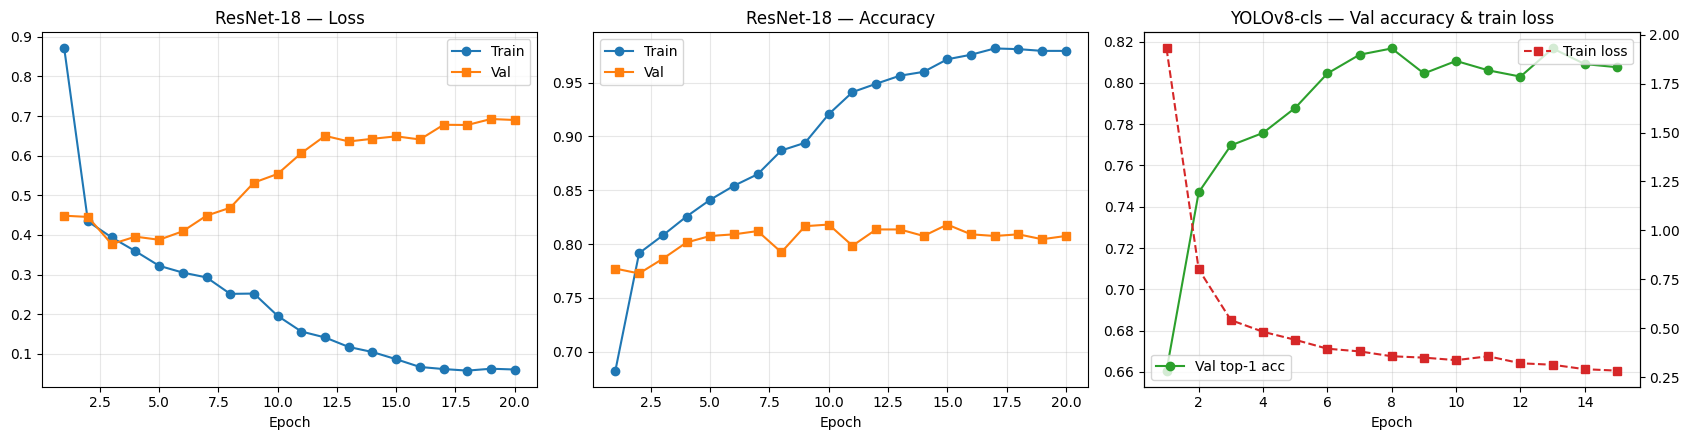

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ep = range(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], "o-", label="Train"); axes[0].plot(ep, history["val_loss"], "s-", label="Val")
axes[0].set_title(f"{CNN_NAME} — Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(ep, history["train_acc"], "o-", label="Train"); axes[1].plot(ep, history["val_acc"], "s-", label="Val")
axes[1].set_title(f"{CNN_NAME} — Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=.3)

try:
    ycsv = pd.read_csv(RUNS_DIR / "yolov8_cls" / "results.csv"); ycsv.columns = [c.strip() for c in ycsv.columns]
    axes[2].plot(ycsv["epoch"], ycsv["metrics/accuracy_top1"], "o-", color="tab:green", label="Val top-1 acc")
    ax2 = axes[2].twinx(); ax2.plot(ycsv["epoch"], ycsv["train/loss"], "s--", color="tab:red", label="Train loss")
    axes[2].legend(loc="lower left"); ax2.legend(loc="upper right")
except Exception as e:
    print("Could not plot YOLO curves:", e, "| columns:", list(ycsv.columns) if "ycsv" in globals() else "n/a")
axes[2].set_title("YOLOv8-cls — Val accuracy & train loss"); axes[2].set_xlabel("Epoch"); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "training_curves_comparison.png", dpi=150); plt.show()

## 8. Shared Prediction Helpers

One place that turns an image (path or PIL) into class probabilities for each model — used by the test evaluation **and** by the interactive diagnosis tool — plus the **two-stage reading**: first the **plant**, then the **disease within that plant**.

In [14]:
YOLO_DEV = 0 if torch.cuda.is_available() else "cpu"
_yolo_to_ours = {i: CLASS_NAMES.index(n) for i, n in yolo_model.names.items()}

def yolo_predict_probs(sources, batch=64):
    # sources: list of file paths or PIL images -> (n, NUM_CLASSES) probabilities
    out = np.zeros((len(sources), NUM_CLASSES), dtype=np.float32)
    for i in range(0, len(sources), batch):
        res = yolo_model.predict(sources[i:i+batch], imgsz=IMG_SIZE, verbose=False, device=YOLO_DEV)
        for j, r in enumerate(res):
            p = r.probs.data.cpu().numpy()
            for yi, oi in _yolo_to_ours.items():
                out[i + j, oi] = p[yi]
    return out

def cnn_predict_probs_pil(img):
    x = eval_transform(img.convert("RGB")).unsqueeze(0).to(device)
    cnn_model.eval()
    with torch.no_grad():
        return F.softmax(cnn_model(x), 1)[0].cpu().numpy(), x

def two_stage(probs):
    # Stage 1: which plant?  Stage 2: which disease, among that plant's classes only.
    crop_p = probs @ CROP_MATRIX
    ci = int(crop_p.argmax())
    mask = (CLASS_CROP_IDX == ci)
    masked = probs * mask
    k = int(masked.argmax())
    return {"crop": CROPS_LIST[ci], "crop_conf": float(crop_p[ci] / crop_p.sum()),
            "disease": CLASS_DISEASE[k], "disease_conf": float(probs[k] / probs[mask].sum()),
            "class_idx": k}
print("Helpers ready.")

Helpers ready.


## 9. Quantitative Evaluation on the Held-Out Test Set

For **YOLOv8**, the **CNN**, and their **Ensemble** (average of the two probability vectors) we report three levels:
- **Plant accuracy** – is the crop correct? (tomato vs corn vs potato …)
- **Class accuracy** – are plant *and* disease both correct?
- **Macro-F1** – averaged over all classes, so rare classes count equally.

In [15]:
test_paths  = [p for p, _ in test_dataset.samples]
test_labels = np.array(test_dataset.targets)
test_crop_true = CLASS_CROP_IDX[test_labels]

yolo_probs = yolo_predict_probs(test_paths)
cnn_probs = []
cnn_model.eval()
with torch.no_grad():
    for x, _ in test_loader:
        cnn_probs.append(F.softmax(cnn_model(x.to(device)), 1).cpu().numpy())
cnn_probs = np.concatenate(cnn_probs)
ens_probs = (yolo_probs + cnn_probs) / 2

results = {}
for name, pr in [("YOLOv8-cls", yolo_probs), (CNN_NAME, cnn_probs), ("Ensemble", ens_probs)]:
    preds = pr.argmax(1)
    results[name] = {"preds": preds,
                     "class_acc": accuracy_score(test_labels, preds),
                     "crop_acc":  accuracy_score(test_crop_true, CLASS_CROP_IDX[preds]),
                     "macro_f1":  f1_score(test_labels, preds, average="macro")}
    r = results[name]
    print(f"{name:<12} | Plant acc {r['crop_acc']*100:6.2f}% | Class acc (plant+disease) {r['class_acc']*100:6.2f}% | Macro-F1 {r['macro_f1']*100:6.2f}%")

print("\nDetailed per-class report — Ensemble")
print(classification_report(test_labels, results["Ensemble"]["preds"], labels=range(NUM_CLASSES),
                            target_names=CLASS_NAMES, digits=3, zero_division=0))

YOLOv8-cls   | Plant acc  99.85% | Class acc (plant+disease)  79.39% | Macro-F1  78.93%
ResNet-18    | Plant acc 100.00% | Class acc (plant+disease)  80.30% | Macro-F1  80.18%
Ensemble     | Plant acc 100.00% | Class acc (plant+disease)  80.76% | Macro-F1  80.68%

Detailed per-class report — Ensemble
                               precision    recall  f1-score   support

        Corn (maize)___Blight      0.885     0.900     0.893        60
   Corn (maize)___Common Rust      0.968     1.000     0.984        60
Corn (maize)___Gray Leaf Spot      0.912     0.867     0.889        60
       Corn (maize)___Healthy      1.000     1.000     1.000        60
       Rice___Bacterialblight      1.000     1.000     1.000        60
                 Rice___Blast      1.000     0.967     0.983        60
             Rice___Brownspot      0.968     1.000     0.984        60
                Rice___Tungro      1.000     1.000     1.000        60
                Tomato___Test      0.358     0.400     0.3

## 10. Per-Crop Breakdown & Confusion Matrices

Accuracy for each plant separately shows which crops are easy and which are hard — a multi-crop test is more informative than a single-crop one.

,Crop,Test images,YOLOv8-cls class acc (%),ResNet-18 class acc (%),Ensemble class acc (%)
0,Corn (maize),240,92.08,92.92,94.17
1,Rice,240,98.75,98.75,99.17
2,Tomato,180,36.67,38.89,38.33


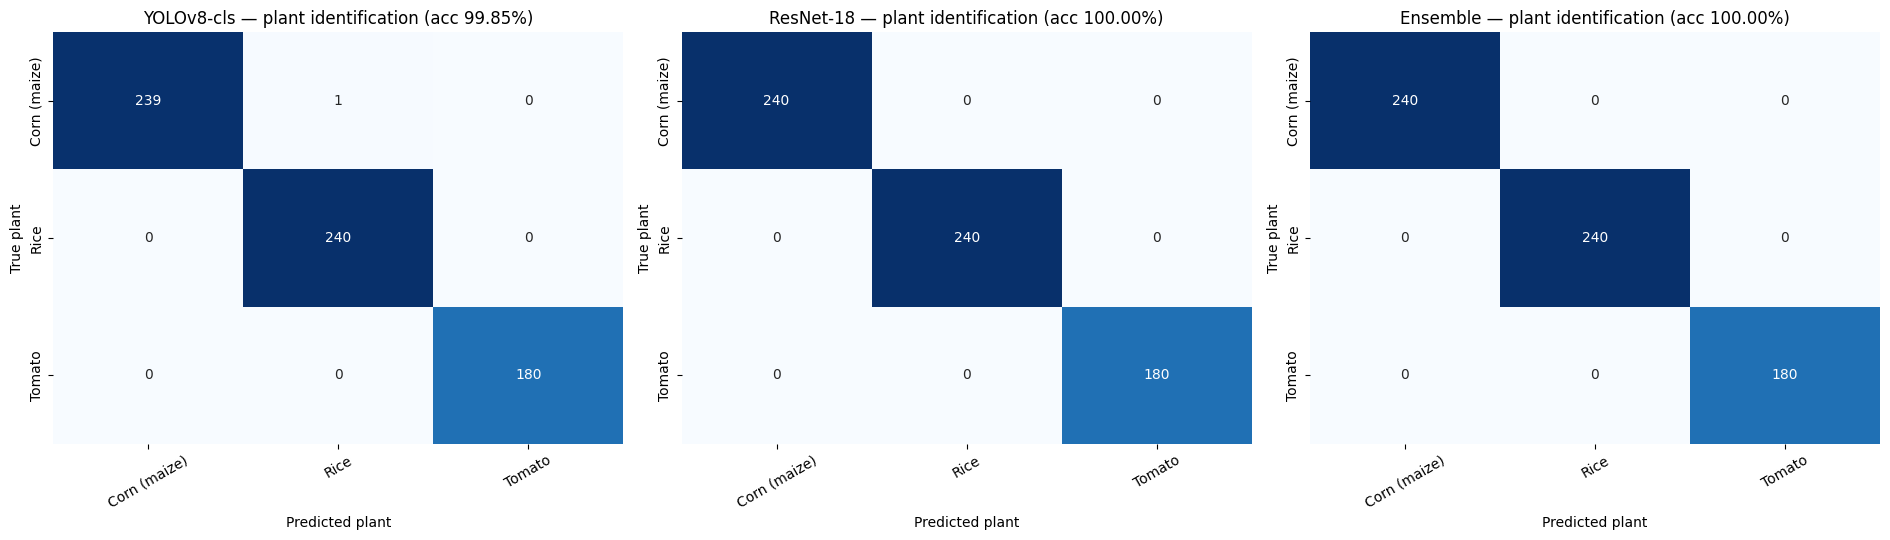

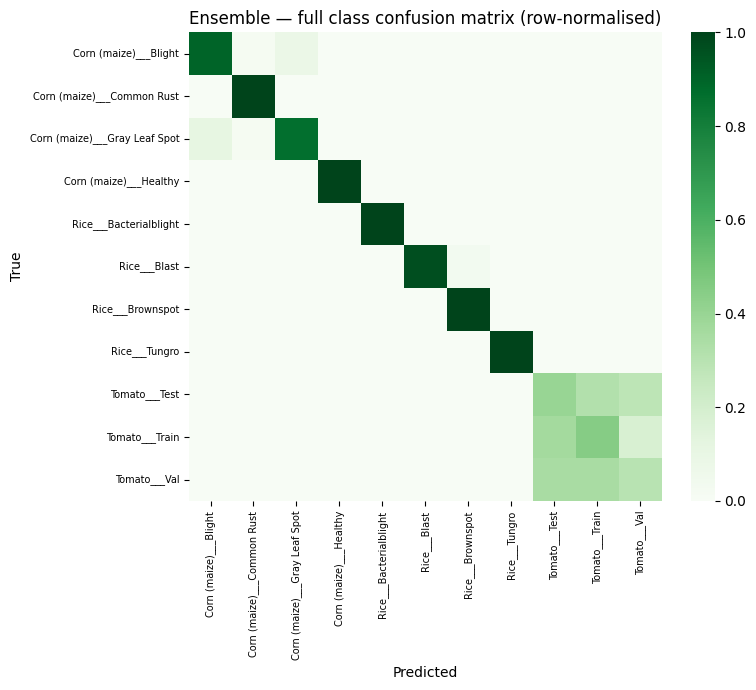

In [16]:
rows = []
for ci, crop in enumerate(CROPS_LIST):
    m = (test_crop_true == ci)
    row = {"Crop": crop, "Test images": int(m.sum())}
    for name in results:
        row[f"{name} class acc (%)"] = round((results[name]["preds"][m] == test_labels[m]).mean() * 100, 2)
    rows.append(row)
per_crop = pd.DataFrame(rows)
per_crop.to_csv(RESULTS_DIR / "per_crop_accuracy.csv", index=False)
display(per_crop)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, name in zip(axes, results):
    cm = confusion_matrix(test_crop_true, CLASS_CROP_IDX[results[name]["preds"]], labels=range(len(CROPS_LIST)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CROPS_LIST, yticklabels=CROPS_LIST, ax=ax, cbar=False)
    ax.set_title(f"{name} — plant identification (acc {results[name]['crop_acc']*100:.2f}%)")
    ax.set_xlabel("Predicted plant"); ax.set_ylabel("True plant"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confusion_matrix_crops.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(max(8, 0.45 * NUM_CLASSES), max(7, 0.4 * NUM_CLASSES)))
cm = confusion_matrix(test_labels, results["Ensemble"]["preds"], labels=range(NUM_CLASSES)).astype(float)
cm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
sns.heatmap(cm, cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax, vmin=0, vmax=1)
ax.set_title("Ensemble — full class confusion matrix (row-normalised)"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.xticks(rotation=90, fontsize=7); plt.yticks(fontsize=7)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confusion_matrix_full.png", dpi=150); plt.show()

## 11. Explainable AI: Grad-CAM

Grad-CAM weights the last convolutional feature maps by the gradient of the class score:  
$\alpha_k^c=\frac1Z\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}$, $\quad L^c=\mathrm{ReLU}\left(\sum_k\alpha_k^c A^k\right)$  
and overlays the result on the leaf, showing which regions drove the decision.

In [17]:
# Remove ANY hooks left on the model by earlier runs of this cell
for _m in cnn_model.modules():
    _m._forward_hooks.clear()
    _m._backward_hooks.clear()

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.h = target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inp, out):
        self.activations = out.detach()
        if out.requires_grad:   # skipped under torch.no_grad()
            out.register_hook(lambda g: setattr(self, "gradients", g.detach()))

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        x = input_tensor.clone().requires_grad_(True)
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = int(logits.argmax(1).item())
        logits[0, class_idx].backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=input_tensor.shape[2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, F.softmax(logits, 1)[0].detach().cpu().numpy()

    def remove(self):
        self.h.remove()

gradcam = GradCAM(cnn_model, gradcam_target(cnn_model))

def denorm(t):
    img = t.squeeze().cpu().permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    return np.clip(img, 0, 1)

def overlay(img, cam, alpha=0.45):
    heat = plt.cm.jet(cam)[..., :3]
    return np.clip((1 - alpha) * img + alpha * heat, 0, 1)

print(f"Grad-CAM ready on the {CNN_NAME} last convolutional block.")

Grad-CAM ready on the ResNet-18 last convolutional block.


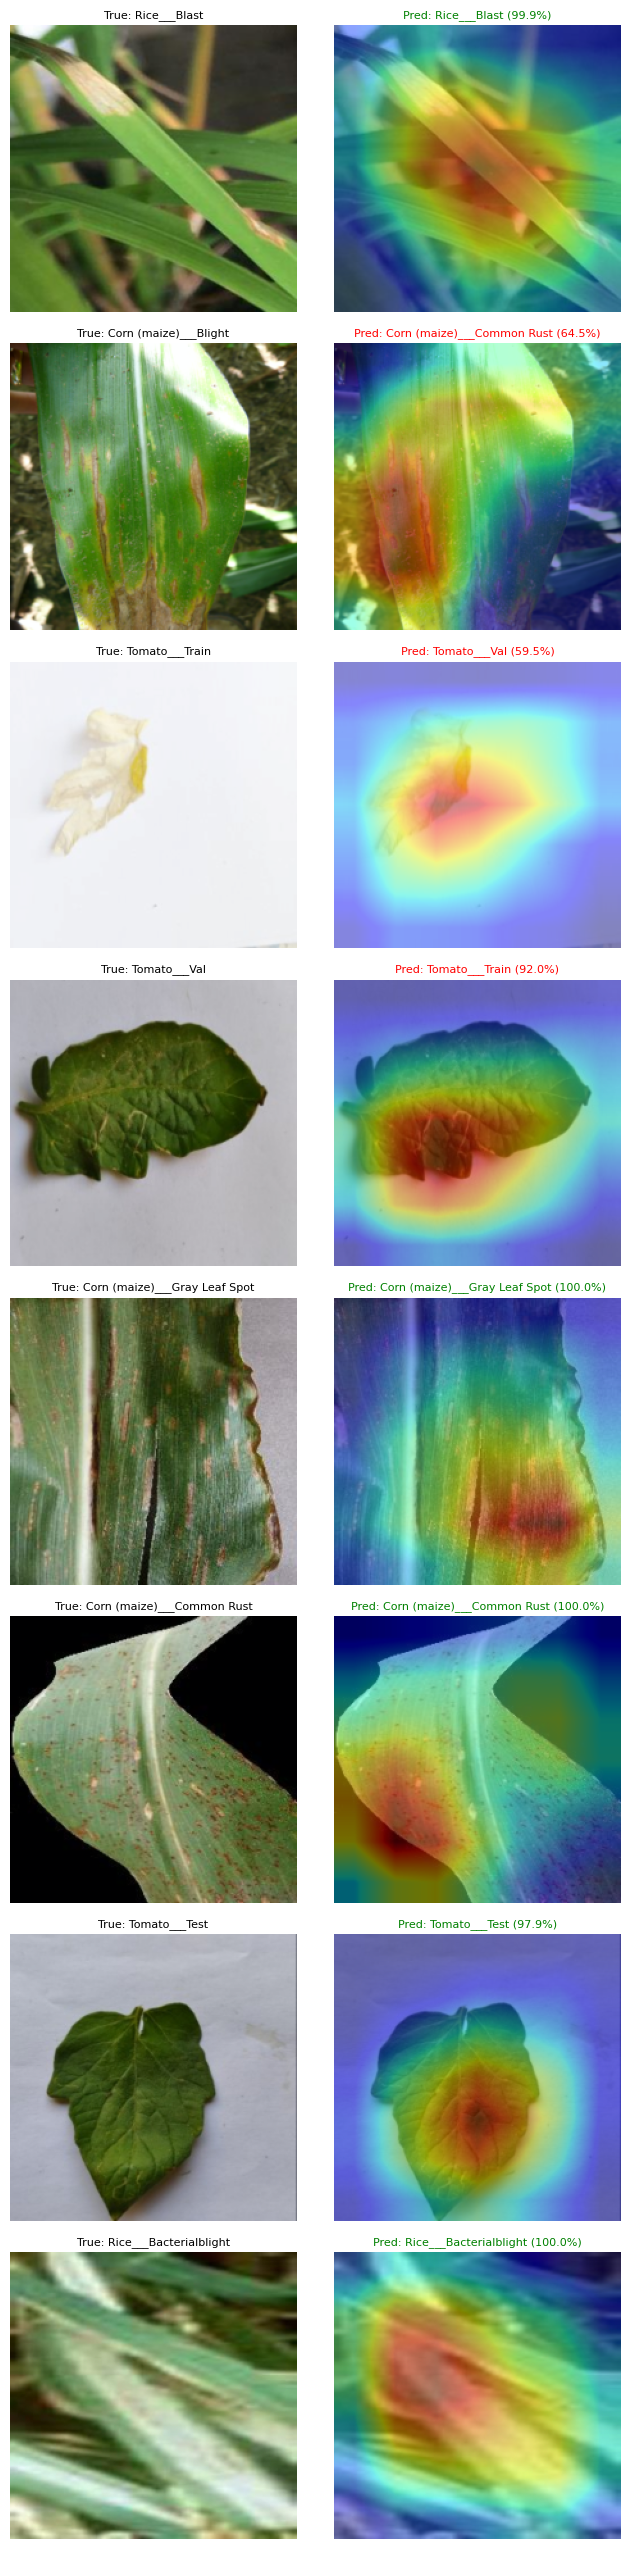

In [18]:
# Grad-CAM examples: one random test image from up to 8 different classes
rng = np.random.RandomState(RANDOM_SEED)
show_classes = rng.choice(NUM_CLASSES, size=min(8, NUM_CLASSES), replace=False)
fig, axes = plt.subplots(len(show_classes), 2, figsize=(7, 3.2 * len(show_classes)))
axes = np.atleast_2d(axes)
for r, ci in enumerate(show_classes):
    idx = rng.choice(np.where(test_labels == ci)[0])
    x, y = test_dataset[idx]
    cam, pred, probs = gradcam.generate(x.unsqueeze(0).to(device))
    img = denorm(x)
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"True: {CLASS_NAMES[y]}", fontsize=8)
    axes[r, 1].imshow(overlay(img, cam))
    axes[r, 1].set_title(f"Pred: {CLASS_NAMES[pred]} ({probs[pred]*100:.1f}%)", fontsize=8,
                         color="green" if pred == y else "red")
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "gradcam_visualizations.png", dpi=150); plt.show()

## 12. Leaf Diagnosis Tool — pick a leaf photo, get plant + disease

`diagnose_leaf(path_or_image)` does the whole pipeline for one image:
1. **YOLOv8** and the **CNN** each produce class probabilities.
2. The probabilities are **averaged** (ensemble).
3. **Stage 1 – plant**: the crop with the highest summed probability (tomato, corn, potato …).
4. **Stage 2 – disease**: the best disease *within that plant*.
5. **Grad-CAM** shows where the CNN looked; an **agreement check** flags cases where the two models disagree.

> The system can only recognise the crops and diseases it was trained on. A leaf from an unsupported plant gets a low-confidence result, and the tool warns when confidence is low.

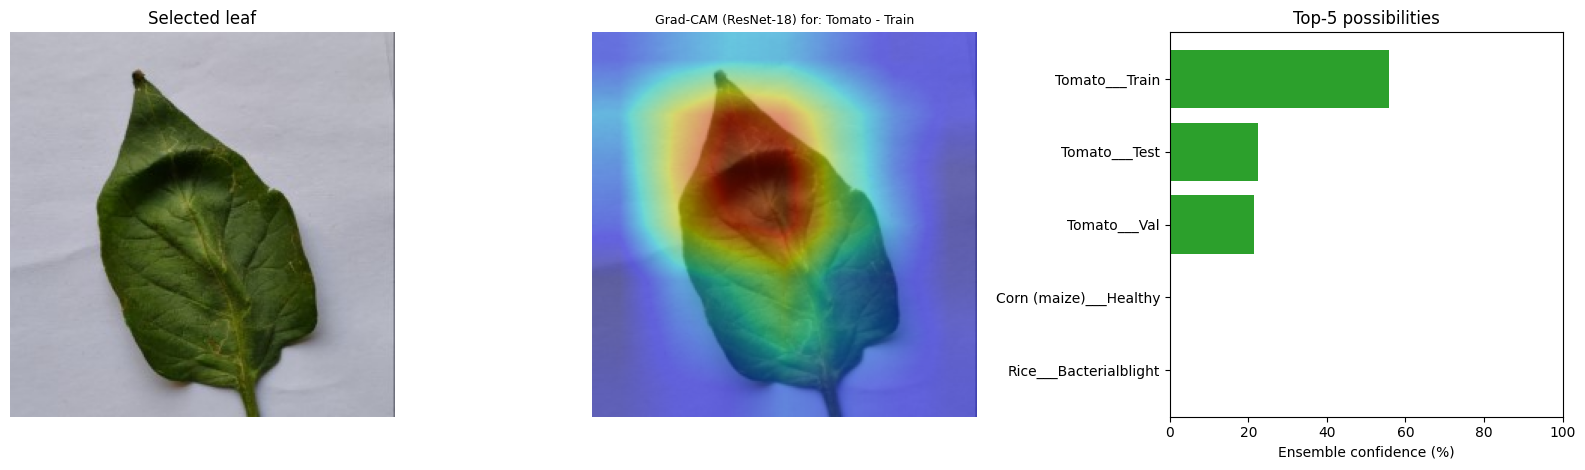

  PLANT   : Tomato   (confidence 99.5%)
  DISEASE : Train   (confidence 56.0%)
  YOLOv8       -> Tomato / Train  (66.3%)
  ResNet-18    -> Tomato / Train  (45.5%)
  Agreement    : Both models AGREE


In [19]:
def diagnose_leaf(image_source, show=True):
    img = image_source if isinstance(image_source, Image.Image) else Image.open(image_source)
    img = img.convert("RGB")

    yp = yolo_predict_probs([img])[0]
    cp, x = cnn_predict_probs_pil(img)
    ep = (yp + cp) / 2
    Y, C, E = two_stage(yp), two_stage(cp), two_stage(ep)

    if Y["crop"] == C["crop"] and Y["disease"] == C["disease"]:
        status = "Both models AGREE"
    elif Y["crop"] == C["crop"]:
        status = "Same plant, different disease - please review"
    else:
        status = "Models disagree on the plant - please review"
    low = E["crop_conf"] < 0.60 or E["disease_conf"] < 0.50

    cam, _, _ = gradcam.generate(x, class_idx=E["class_idx"])
    base = denorm(x)

    if show:
        fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
        axes[0].imshow(img); axes[0].set_title("Selected leaf"); axes[0].axis("off")
        axes[1].imshow(overlay(base, cam)); axes[1].set_title(f"Grad-CAM ({CNN_NAME}) for: {E['crop']} - {E['disease']}", fontsize=9)
        axes[1].axis("off")
        top = np.argsort(ep)[::-1][:5]
        axes[2].barh([CLASS_NAMES[i] for i in top][::-1], [ep[i] * 100 for i in top][::-1], color="tab:green")
        axes[2].set_xlim(0, 100); axes[2].set_xlabel("Ensemble confidence (%)"); axes[2].set_title("Top-5 possibilities")
        plt.tight_layout(); plt.show()

    print("=" * 62)
    print(f"  PLANT   : {E['crop']}   (confidence {E['crop_conf']*100:.1f}%)")
    print(f"  DISEASE : {E['disease']}   (confidence {E['disease_conf']*100:.1f}%)")
    print("=" * 62)
    print(f"  YOLOv8       -> {Y['crop']} / {Y['disease']}  ({Y['disease_conf']*100:.1f}%)")
    print(f"  {CNN_NAME:<12} -> {C['crop']} / {C['disease']}  ({C['disease_conf']*100:.1f}%)")
    print(f"  Agreement    : {status}")
    if low:
        print("  WARNING      : low confidence - this leaf may be a plant/disease the model was not trained on.")
    return {"ensemble": E, "yolo": Y, "cnn": C, "status": status}

# Quick demo on a random test image (no upload needed)
_demo = diagnose_leaf(test_paths[int(np.random.RandomState(0).randint(len(test_paths)))])

### 12.1 Choose a leaf image manually

**Option A – Upload from your computer** (Colab): uncomment `upload_and_diagnose()` in the next cell, run it, and pick a leaf photo.  
**Option B – From Google Drive / local path**: `diagnose_leaf("/content/drive/MyDrive/my_leaf.jpg")`.

In [20]:
def upload_and_diagnose():
    # Colab: opens an upload button, then runs the full diagnosis on each uploaded photo.
    if not IN_COLAB:
        print("Not running in Colab - call diagnose_leaf(r'path/to/leaf.jpg') instead.")
        return
    from google.colab import files
    uploaded = files.upload()
    for name, data in uploaded.items():
        path = UPLOAD_DIR / name
        path.write_bytes(data)
        print(f"Selected: {name}")
        diagnose_leaf(path)

# upload_and_diagnose()     # <- uncomment, run, then click "Choose files"

## 13. Comparative Benchmarking

Everything below is measured in this run (latency = single image, averaged over 30 runs after warm-up).

In [21]:
def latency_ms(fn, n=30, warmup=5):
    for _ in range(warmup): fn()
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(n): fn()
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / n * 1000

sample_path = test_paths[0]
sample_x = test_dataset[0][0].unsqueeze(0).to(device)
yolo_lat = latency_ms(lambda: yolo_model.predict(sample_path, imgsz=IMG_SIZE, verbose=False, device=YOLO_DEV))
with torch.no_grad():
    cnn_lat = latency_ms(lambda: cnn_model(sample_x))

y_mb = (MODELS_DIR / "best_yolov8n_cls.pt").stat().st_size / 1e6
c_mb = CNN_BEST.stat().st_size / 1e6
def row(name, params, mb, r, lat, tt):
    return {"Model": name, "Parameters (M)": round(params / 1e6, 2), "Size (MB)": round(mb, 2),
            "Plant acc (%)": round(r["crop_acc"] * 100, 2), "Class acc (%)": round(r["class_acc"] * 100, 2),
            "Macro-F1 (%)": round(r["macro_f1"] * 100, 2), "Latency (ms)": round(lat, 2), "Train time (s)": round(tt, 1)}

df = pd.DataFrame([
    row("YOLOv8n-cls (Model 1)", y_total, y_mb, results["YOLOv8-cls"], yolo_lat, yolo_train_time),
    row(f"{CNN_NAME} + Grad-CAM (Model 2)", c_total, c_mb, results[CNN_NAME], cnn_lat, cnn_train_time),
    row("Ensemble (both)", y_total + c_total, y_mb + c_mb, results["Ensemble"], yolo_lat + cnn_lat, yolo_train_time + cnn_train_time),
])
df.to_csv(RESULTS_DIR / "model_comparison_metrics.csv", index=False)
print(f"MODEL COMPARISON — {len(CROPS_LIST)} crops, {NUM_CLASSES} classes, {len(test_dataset)} test images")
display(df.set_index("Model").T)

MODEL COMPARISON — 3 crops, 11 classes, 660 test images


Model,YOLOv8n-cls (Model 1),ResNet-18 + Grad-CAM (Model 2),Ensemble (both)
Parameters (M),1.45,11.31,12.76
Size (MB),2.99,45.32,48.31
Plant acc (%),99.85,100.00,100.00
Class acc (%),79.39,80.30,80.76
Macro-F1 (%),78.93,80.18,80.68
Latency (ms),5.89,6.20,12.10
Train time (s),320.70,358.00,678.60


## 14. Discussion, Limitations & Future Work

The cell below writes the headline findings from the measured results so the text always matches the numbers.

In [22]:
y, c, e = df.iloc[0], df.iloc[1], df.iloc[2]
print(f"1. Plant identification: YOLOv8 {y['Plant acc (%)']}% | {CNN_NAME} {c['Plant acc (%)']}% | Ensemble {e['Plant acc (%)']}%.")
print(f"2. Plant + disease: YOLOv8 {y['Class acc (%)']}% | {CNN_NAME} {c['Class acc (%)']}% | Ensemble {e['Class acc (%)']}% "
      f"(macro-F1 {y['Macro-F1 (%)']} / {c['Macro-F1 (%)']} / {e['Macro-F1 (%)']}).")
best = per_crop.set_index("Crop")["Ensemble class acc (%)"]
print(f"3. Easiest crop: {best.idxmax()} ({best.max()}%) | hardest crop: {best.idxmin()} ({best.min()}%) (ensemble).")
agree = (yolo_probs.argmax(1) == cnn_probs.argmax(1))
print(f"4. The two models agree on {agree.mean()*100:.1f}% of test images; ensemble accuracy on agreed images "
      f"{(results['Ensemble']['preds'][agree] == test_labels[agree]).mean()*100:.1f}%.")
print(f"5. Size / speed: YOLOv8 {y['Parameters (M)']}M params, {y['Latency (ms)']} ms | {CNN_NAME} {c['Parameters (M)']}M params, {c['Latency (ms)']} ms.")

1. Plant identification: YOLOv8 99.85% | ResNet-18 100.0% | Ensemble 100.0%.
2. Plant + disease: YOLOv8 79.39% | ResNet-18 80.3% | Ensemble 80.76% (macro-F1 78.93 / 80.18 / 80.68).
3. Easiest crop: Rice (99.17%) | hardest crop: Tomato (38.33%) (ensemble).
4. The two models agree on 82.6% of test images; ensemble accuracy on agreed images 89.0%.
5. Size / speed: YOLOv8 1.45M params, 5.89 ms | ResNet-18 11.31M params, 6.2 ms.


### Discussion
- **Why multi-crop is a stronger test.** With one crop the model only separates diseases; with many crops it must also tell the plants apart, and similar-looking diseases on different plants (e.g. blights on tomato vs potato) can be confused. The per-crop table and crop-level confusion matrices show exactly where.
- **Two-stage reading.** Choosing the plant first and then the disease *within that plant* avoids impossible answers such as a corn leaf diagnosed with a tomato-only disease.
- **Ensemble and explainability.** Averaging two different architectures usually improves robustness, disagreement is a useful "please review" signal, and Grad-CAM lets a user check that the CNN looked at the leaf lesion rather than the background.

### Limitations (please state these honestly in the report)
- **Dataset bias.** PlantVillage-style images are single leaves on plain backgrounds, so test accuracy there is optimistic compared with photos taken in a field. A field-condition dataset (e.g. PlantDoc) or your own phone photos would give a more realistic picture.
- **Closed set.** The model only knows the crops/diseases it was trained on; an unseen plant is forced into the closest known class (the low-confidence warning helps but is not a guarantee).
- **Image-level labels.** YOLOv8 is used as a classifier; lesion localisation and counting need bounding-box annotations.
- **Class balance.** Classes are capped to `MAX_PER_CLASS` and the CNN uses a class-weighted loss, but different source datasets may still differ in style.

### Future work
Add more crops/datasets and field images · train YOLOv8 detection on box-annotated data · Grad-CAM++ / Score-CAM · an "unknown plant" rejection class · export to ONNX / TFLite for a mobile app.

## 15. Conclusion & References

We built a multi-crop leaf diagnosis system: the user selects a leaf image, the pipeline identifies the plant, then the disease, using YOLOv8 and a Grad-CAM-enabled CNN, evaluated at plant, class and macro-F1 level on a held-out test set.

1. Quach, L. D., et al. (2024). *Tomato Health Monitoring System … YOLOv8 … Grad-CAM++*. **IEEE Access**, 12.
2. Jocher, G., Chaurasia, A., & Qiu, J. (2023). *Ultralytics YOLOv8*. https://github.com/ultralytics/ultralytics
3. Selvaraju, R. R., et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization*. **ICCV**.
4. Hughes, D. P., & Salathé, M. (2015). *An open access repository of images on plant health to enable the development of mobile disease diagnostics* (PlantVillage). arXiv:1511.08060.
5. Ioffe, S., & Szegedy, C. (2015). *Batch Normalization*. **ICML**.
6. He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition*. **CVPR**. (used when `CNN_BACKBONE = "resnet18"`)

## 16. Save Everything to Google Drive

Models (`models/`) and results (`results/`) are already written to Drive while the notebook runs. This cell also copies the YOLOv8 training folder (curves, confusion matrix, weights) so nothing is lost when the Colab session ends.

In [23]:
yolo_run_src = RUNS_DIR / "yolov8_cls"
if yolo_run_src.exists():
    shutil.copytree(yolo_run_src, OUT_DIR / "yolov8_cls_run", dirs_exist_ok=True)
print("Saved to Drive:", OUT_DIR.resolve())
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file() and p.suffix in {".pt", ".pth", ".png", ".csv", ".json", ".txt"} and "yolov8_cls_run" not in str(p):
        print("  ", p.relative_to(OUT_DIR))

Saved to Drive: /content/drive/MyDrive/PlantDisease_Output
   models/best_cnn_plant_model.pth
   models/best_yolov8n_cls.pt
   models/classes.json
   results/bad_images.txt
   results/class_distribution.png
   results/confusion_matrix_crops.png
   results/confusion_matrix_full.png
   results/gradcam_visualizations.png
   results/model_comparison_metrics.csv
   results/per_crop_accuracy.csv
   results/training_curves_comparison.png
